In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
target = 'ClosePrice'

def n_months(path):
    return int(re.search(r'train_(\d+)m', path).group(1))

# fe_outputs/train_6m ... train_30m, each with features_train/val/test.csv
split_dirs = sorted(
    (d for d in glob.glob('fe_outputs/train_*m') if 6 <= n_months(d) <= 30),
    key=n_months,
)
print([n_months(d) for d in split_dirs])

# columns that must never be model features. Any column with "date" in its
# name is also excluded.
EXCLUDE_COLS = ["CloseDate"]
_warned = set()

def load_split(folder):
    """Load train/val/test for one window and return numeric features + target."""
    train = pd.read_csv(f"{folder}/features_train.csv")
    val = pd.read_csv(f"{folder}/features_val.csv")
    test = pd.read_csv(f"{folder}/features_test.csv")

    # never use close date (or anything derived from it) as a feature, plus
    # any non-numeric column (dates, IDs, text); chosen from train
    banned = [c for c in train.columns
              if c in EXCLUDE_COLS or "date" in c.lower()]
    feats = (train.drop(columns=[target] + banned)
                  .select_dtypes(include="number").columns)
    dropped = [c for c in train.columns if c != target and c not in feats]
    if dropped and tuple(dropped) not in _warned:
        _warned.add(tuple(dropped))
        print(f"Excluded from features: {dropped}")

    X_tr, X_val, X_te = (
        df[feats].replace([np.inf, -np.inf], np.nan) for df in (train, val, test)
    )

    # fill any missing values with train-set medians (same fill for all splits)
    med = X_tr.median()
    X_tr, X_val, X_te = X_tr.fillna(med), X_val.fillna(med), X_te.fillna(med)

    return X_tr, train[target], X_val, val[target], X_te, test[target]


[6, 9, 12, 15, 18, 21, 24, 27]


In [3]:
def metrics(y_true, y_pred):
    ape = np.abs(y_pred - y_true) / y_true
    mse = mean_squared_error(y_true, y_pred)
    return {
        'R2': r2_score(y_true, y_pred),
        'MAPE_%': ape.mean() * 100,
        'MdAPE_%': np.median(ape) * 100,
        'MAE_$': mean_absolute_error(y_true, y_pred),
        'MSE_$2': mse,
        'RMSE_$': np.sqrt(mse),
    }

rows = []
for d in split_dirs:
    X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(d)

    m = LinearRegression().fit(X_tr, y_tr)
    val_pred = m.predict(X_val)
    pred = m.predict(X_te)
    rows.append({
        'model': 'LinearRegression',
        'n_train_months': n_months(d),
        'n_train_rows': len(X_tr),
        'train_R2': r2_score(y_tr, m.predict(X_tr)),
        **{f'val_{k}': v for k, v in metrics(y_val, val_pred).items()},
        'val_neg_preds': int((val_pred <= 0).sum()),
        **{f'test_{k}': v for k, v in metrics(y_te, pred).items()},
        'neg_preds': int((pred <= 0).sum()),
    }
)

results = pd.DataFrame(rows)
results.to_csv('baseline_results.csv', index=False)
results

Excluded from features: ['CloseDate']


,model,n_train_months,n_train_rows,train_R2,val_R2,val_MAPE_%,val_MdAPE_%,val_MAE_$,val_MSE_$2,val_RMSE_$,val_neg_preds,test_R2,test_MAPE_%,test_MdAPE_%,test_MAE_$,test_MSE_$2,test_RMSE_$,neg_preds
0,LinearRegression,6,64566,0.757019,0.783974,19.665781,13.798817,245096.881788,4.327413e+11,657830.726649,0,0.821370,20.167901,14.247431,249847.985654,3.547365e+11,595597.638983,1
1,LinearRegression,9,96739,0.759752,0.784283,19.544627,13.409775,242403.009194,4.321216e+11,657359.566247,0,0.821008,20.200694,14.111627,248025.695596,3.554558e+11,596201.149927,1
2,LinearRegression,12,131702,0.763969,0.784462,19.431422,13.241781,240713.055270,4.317635e+11,657087.163748,0,0.820897,20.107190,13.957118,246541.141199,3.556755e+11,596385.334724,1
3,LinearRegression,15,166979,0.766246,0.784595,19.092228,13.205503,240063.730544,4.314965e+11,656883.925371,0,0.821593,19.629202,13.759902,245065.445826,3.542945e+11,595226.453876,1
4,LinearRegression,18,194532,0.773818,0.784720,18.672463,13.281149,238688.173185,4.312470e+11,656693.994283,0,0.821268,19.045430,13.663364,242870.017007,3.549390e+11,595767.556782,1
5,LinearRegression,21,228140,0.775287,0.784592,18.591417,13.126780,237443.347913,4.315019e+11,656888.038138,0,0.819859,18.976730,13.489309,241845.572336,3.577367e+11,598110.922427,1
6,LinearRegression,24,264762,0.773789,0.784398,18.425288,13.045310,236096.970946,4.318910e+11,657184.142991,0,0.818938,18.791333,13.444259,240398.049094,3.595661e+11,599638.345465,1
7,LinearRegression,27,303805,0.777852,0.783678,18.262263,13.206835,235583.943082,4.333336e+11,658280.762792,0,0.816930,18.561607,13.535824,239629.262290,3.635542e+11,602954.566315,1


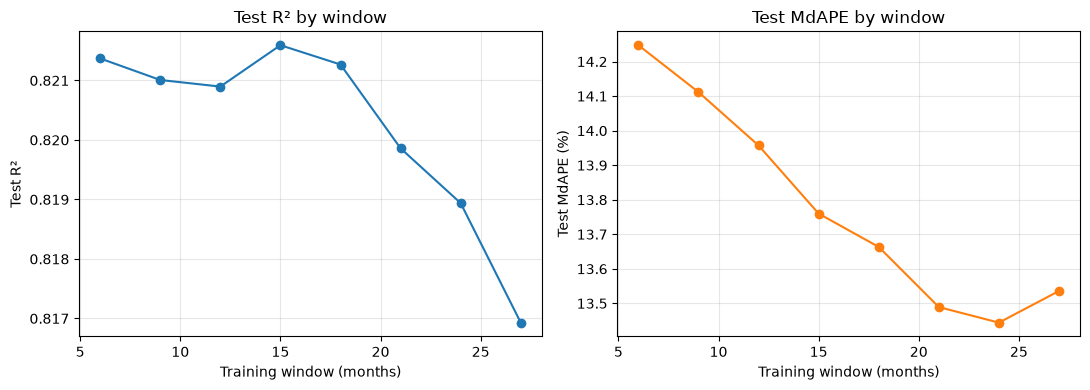

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(results['n_train_months'], results['test_R2'], marker='o')
ax[0].set(xlabel='Training window (months)', ylabel='Test R²', title='Test R² by window')
ax[1].plot(results['n_train_months'], results['test_MdAPE_%'], marker='o', color='tab:orange')
ax[1].set(xlabel='Training window (months)', ylabel='Test MdAPE (%)', title='Test MdAPE by window')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [5]:
BASELINE_N = 15
d = f'fe_outputs/train_{BASELINE_N}m'
X_tr, y_tr, X_val, y_val, X_te, y_te = load_split(d)

lr = LinearRegression().fit(X_tr, y_tr)
val_pred = lr.predict(X_val)
pred = lr.predict(X_te)

pd.DataFrame({'validation': metrics(y_val, val_pred),
              'test': metrics(y_te, pred)}).T

,R2,MAPE_%,MdAPE_%,MAE_$,MSE_$2,RMSE_$
validation,0.784595,19.092228,13.205503,240063.730544,4.314965e+11,656883.925371
test,0.821593,19.629202,13.759902,245065.445826,3.542945e+11,595226.453876


Points on the red dashed line represent perfect predictions. The linear regression model predicts prices reasonably well for low- to mid-priced homes, but it has two limitations:

* **Underpredicts high-priced properties:** Homes selling above roughly $10M are severely underpredicted, causing those data points to fall far below the line.
* **Generates impossible values:** The model predicts negative prices for 228 of the test homes, which is financially impossible.

This proves that home price is not linear across all features, and a straight-line fit cannot capture the steep price growth seen at the high end of the market.


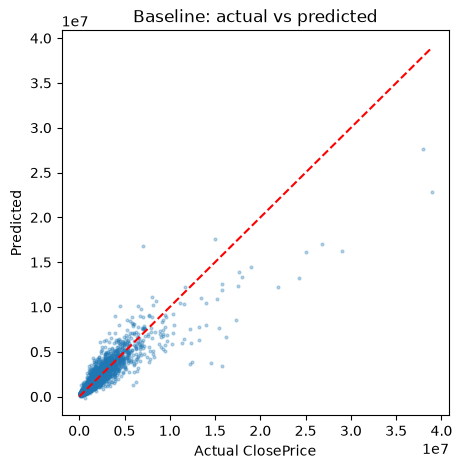

In [6]:
plt.figure(figsize=(5, 5))
plt.scatter(y_te, pred, s=4, alpha=0.3)
lim = [0, y_te.max()]
plt.plot(lim, lim, 'r--')
plt.xlabel('Actual ClosePrice'); plt.ylabel('Predicted'); plt.title('Baseline: actual vs predicted')
plt.show()

## Feature importance

Linear regression coefficients are in the units of each feature (e.g. $ per sq ft vs. $ per bedroom), so raw coefficients can't be compared directly. To rank features fairly, we scale each coefficient by its feature's standard deviation: the standardized effect is the change in predicted price ($) for a one-standard-deviation increase in that feature, holding the others constant.

In [7]:
coefs = pd.Series(lr.coef_, index=X_tr.columns)
importance = pd.DataFrame({
    'coef_raw': coefs,
    'std_dev': X_tr.std(),
    'std_effect_$': coefs * X_tr.std(),   # $ change per +1 std dev of the feature
})
importance['abs_std_effect_$'] = importance['std_effect_$'].abs()
importance = importance.sort_values('abs_std_effect_$', ascending=False)
importance.head(15)

,coef_raw,std_dev,std_effect_$,abs_std_effect_$
est_value_area,1.208249,1.126009e+06,1.360499e+06,1.360499e+06
county_med_ppsf_12m,-858.398968,2.000607e+02,-1.717319e+05,1.717319e+05
LivingArea,-154.805884,1.014728e+03,-1.570858e+05,1.570858e+05
county_med_ppsf_3m,691.396725,2.018815e+02,1.395802e+05,1.395802e+05
age_sq,24.627877,3.007789e+03,7.407547e+04,7.407547e+04
sqft_per_bath,-263.803236,1.984725e+02,-5.235768e+04,5.235768e+04
hoa_monthly,290.855889,1.450664e+02,4.219343e+04,4.219343e+04
sqft_per_bedroom,200.047102,1.966590e+02,3.934107e+04,3.934107e+04
zip_med_ppsf_12m,-128.669663,2.976916e+02,-3.830387e+04,3.830387e+04
area_ppsf_est,-128.669663,2.976916e+02,-3.830387e+04,3.830387e+04


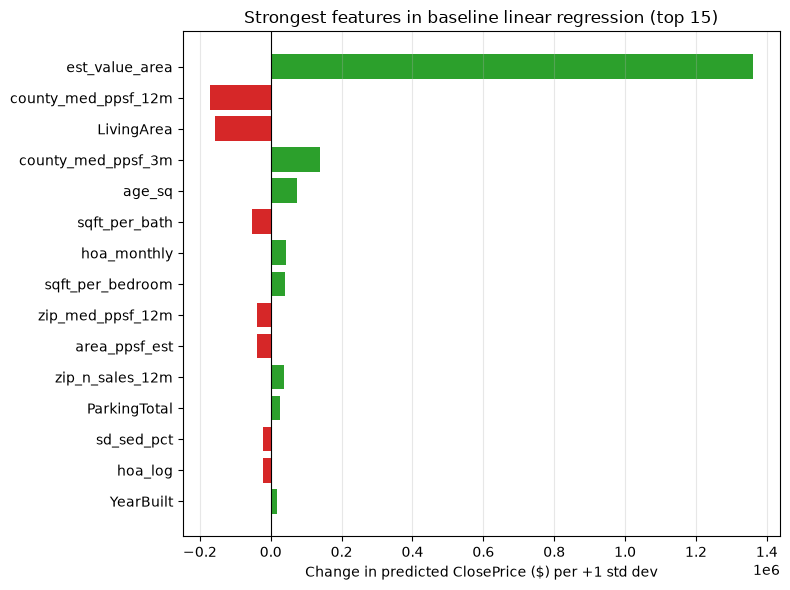

In [8]:
top = importance.head(15).iloc[::-1]
colors = ['tab:green' if v > 0 else 'tab:red' for v in top['std_effect_$']]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top['std_effect_$'], color=colors)
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('Change in predicted ClosePrice ($) per +1 std dev')
plt.title('Strongest features in baseline linear regression (top 15)')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()